# Olympus Tech 4.0 - Part One: Signal in the Static


In [1]:
# Step 0: Install & import
!pip install -q astropy scipy matplotlib numpy pandas

import os, re, glob, shutil, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from astropy.io import fits
from scipy import stats
from scipy.ndimage import (gaussian_filter, label, binary_dilation, maximum_filter,
                           map_coordinates, center_of_mass, sum as ndi_sum)
from scipy.optimize import curve_fit, least_squares
from scipy.special import erf
from IPython.display import display, Markdown
%matplotlib inline

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 250, 'font.size': 10})
rng = np.random.default_rng(42)

TEAM_NAME = "The gentlemen"
FITS_ZIP_PATH = os.environ.get("FITS_ZIP_PATH", "/content/fits.zip")
EXTRACT_DIR = os.environ.get("FITS_EXTRACT_DIR", "/content/extracted_fits")

In [2]:
# Step 1: Extract /content/fits.zip & set up output directories
OUTPUT_BASE = f"{TEAM_NAME}_FITS_outputs"
RAW_FRAMES_DIR = os.path.join(OUTPUT_BASE, "raw_frames")
DIFF_IMAGES_DIR = os.path.join(OUTPUT_BASE, "difference_images")
MEDIAN_REF_PATH = os.path.join(OUTPUT_BASE, "median_reference.png")
TRAJECTORY_PATH = f"{TEAM_NAME}_trajectory1.png"
CSV_SUMMARY_PATH = os.path.join(OUTPUT_BASE, "detected_trajectory_metrics.csv")
DIAG_DIR = os.path.join(OUTPUT_BASE, "diagnostics")

for d in (RAW_FRAMES_DIR, DIFF_IMAGES_DIR, DIAG_DIR):
    os.makedirs(d, exist_ok=True)

if os.path.exists(EXTRACT_DIR):
    shutil.rmtree(EXTRACT_DIR)
os.makedirs(EXTRACT_DIR, exist_ok=True)

if not os.path.exists(FITS_ZIP_PATH):
    raise FileNotFoundError(f"Expected FITS archive at {FITS_ZIP_PATH}. Please upload fits.zip to /content/fits.zip.")

with zipfile.ZipFile(FITS_ZIP_PATH, 'r') as zf:
    zf.extractall(EXTRACT_DIR)

def natural_sort_key(s):
    return [int(text) if text.isdigit() else text.lower() for text in re.split('([0-9]+)', s)]

fits_files = []
for ext in ("*.fits", "*.fit", "*.FITS", "*.FIT", "*.fts"):
    fits_files.extend(glob.glob(os.path.join(EXTRACT_DIR, "**", ext), recursive=True))
fits_files = [f for f in fits_files if "__MACOSX" not in f and not os.path.basename(f).startswith("._")]
fits_files = sorted(set(os.path.abspath(f) for f in fits_files), key=lambda x: natural_sort_key(os.path.basename(x)))

print(f"Extracted {len(fits_files)} FITS files from {FITS_ZIP_PATH}:")
for idx, f in enumerate(fits_files):
    print(f"  Frame {idx:02d} -> {os.path.basename(f)}")

Extracted 20 FITS files from /content/fits.zip:
  Frame 00 -> frame_01.fits
  Frame 01 -> frame_02.fits
  Frame 02 -> frame_03.fits
  Frame 03 -> frame_04.fits
  Frame 04 -> frame_05.fits
  Frame 05 -> frame_06.fits
  Frame 06 -> frame_07.fits
  Frame 07 -> frame_08.fits
  Frame 08 -> frame_09.fits
  Frame 09 -> frame_10.fits
  Frame 10 -> frame_11.fits
  Frame 11 -> frame_12.fits
  Frame 12 -> frame_13.fits
  Frame 13 -> frame_14.fits
  Frame 14 -> frame_15.fits
  Frame 15 -> frame_16.fits
  Frame 16 -> frame_17.fits
  Frame 17 -> frame_18.fits
  Frame 18 -> frame_19.fits
  Frame 19 -> frame_20.fits


Rendered all 20 raw frames (200x200 px) to The gentlemen_FITS_outputs/raw_frames/


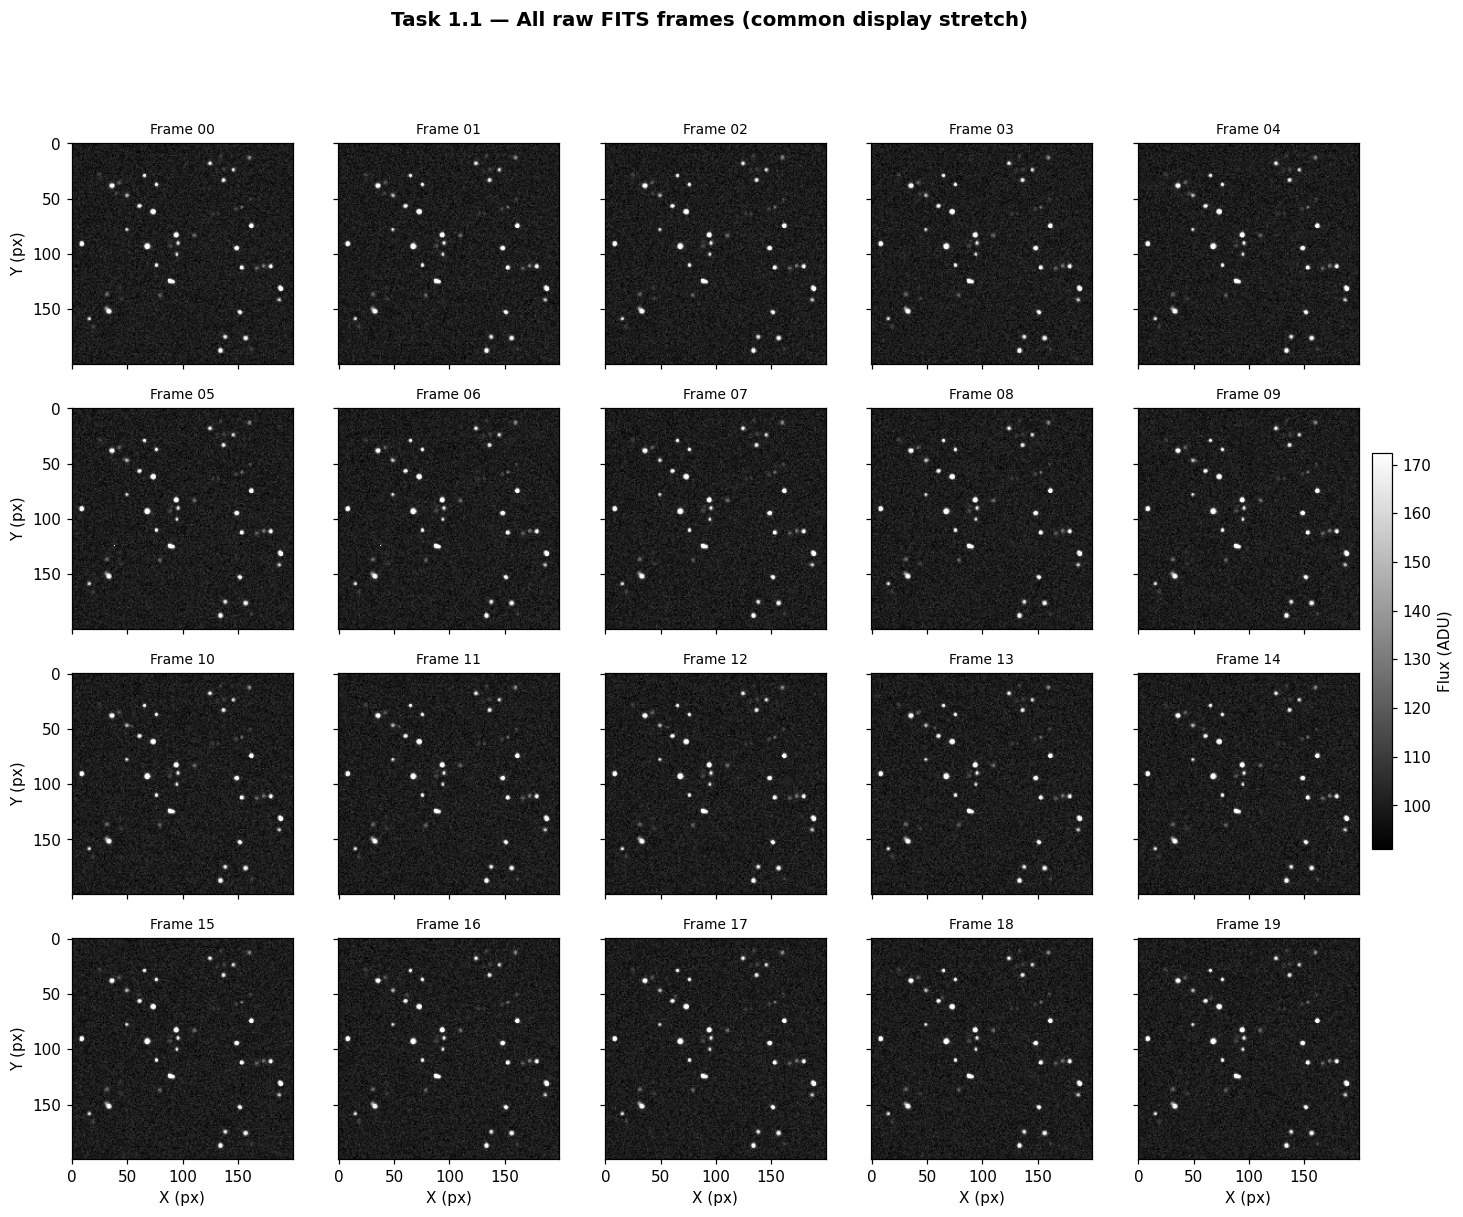

In [3]:
# Step 2: Load FITS frames, save every raw frame (Task 1.1) and show an inline montage
frames, headers, frame_names = [], [], []
for idx, fpath in enumerate(fits_files):
    with fits.open(fpath) as hdul:
        img_data, hdr = None, None
        for hdu in hdul:
            if hdu.data is not None and hdu.data.ndim >= 2:
                img_data = np.squeeze(hdu.data).astype(np.float64)
                hdr = hdu.header
                break
    if img_data is None:
        continue
    if np.isnan(img_data).any():
        img_data = np.nan_to_num(img_data, nan=np.nanmedian(img_data))
    frames.append(img_data); headers.append(hdr)
    fname = os.path.splitext(os.path.basename(fpath))[0]
    frame_names.append(fname)

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    vmin, vmax = np.percentile(img_data, [1.0, 99.5])
    im = ax.imshow(img_data, cmap='gray', vmin=vmin, vmax=vmax, origin='upper')
    ax.set_title(f"Raw FITS Frame {idx:02d} ({fname})")
    ax.set_xlabel("X Position (pixels)"); ax.set_ylabel("Y Position (pixels)")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("Pixel Intensity / Flux (ADU)")
    fig.savefig(os.path.join(RAW_FRAMES_DIR, f"raw_frame_{idx:02d}.png"), bbox_inches='tight')
    plt.close(fig)

frames_stack = np.array(frames)
N_frames, H, W = frames_stack.shape
t_arr = np.arange(N_frames)
print(f"Rendered all {N_frames} raw frames ({H}x{W} px) to {RAW_FRAMES_DIR}/")

def montage(stack, title, cbar_label, cmap='gray', vmin=None, vmax=None, marks=None, path=None, ncols=5):
    nrows = int(np.ceil(len(stack) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.1 * ncols, 3.0 * nrows), sharex=True, sharey=True)
    axes = np.atleast_2d(axes)
    for i, ax in enumerate(axes.flat):
        if i >= len(stack):
            ax.axis('off'); continue
        im = ax.imshow(stack[i], cmap=cmap, vmin=vmin, vmax=vmax, origin='upper')
        ax.set_title(f"Frame {i:02d}", fontsize=9)
        if marks is not None:
            ax.add_patch(Circle(marks[i], 6, fill=False, ec='lime', lw=1.0))
    for ax in axes[-1]: ax.set_xlabel("X (px)")
    for ax in axes[:, 0]: ax.set_ylabel("Y (px)")
    fig.colorbar(im, ax=axes, fraction=0.015, pad=0.01).set_label(cbar_label)
    fig.suptitle(title, fontsize=13, fontweight='bold')
    if path: fig.savefig(path, bbox_inches='tight', dpi=110)
    plt.show()

vmin_all, vmax_all = np.percentile(frames_stack, [1.0, 99.5])
montage(frames_stack, "Task 1.1   All raw FITS frames (common display stretch)", "Flux (ADU)",
        vmin=vmin_all, vmax=vmax_all, path=os.path.join(DIAG_DIR, "raw_frames_montage.png"))

In [4]:
# Step 3: Plain median reference & difference images (v3 method, used for detection & the baseline)
def sigma_clipped_stats(data, sigma=3.0, iters=4):

    arr = np.asarray(data).ravel()
    arr = arr[np.isfinite(arr)]
    mask = np.ones_like(arr, dtype=bool)
    for _ in range(iters):
        valid = arr[mask]
        med = np.median(valid)
        mad_std = 1.4826 * np.median(np.abs(valid - med))
        mask = np.abs(arr - med) < (sigma * mad_std)
    valid = arr[mask]
    med = float(np.median(valid))
    return med, float(1.4826 * np.median(np.abs(valid - med)))

clipped_bg = np.array([sigma_clipped_stats(f)[0] for f in frames_stack])[:, None, None]
global_bg = float(np.median(clipped_bg))
normalized_stack = frames_stack - clipped_bg + global_bg
median_reference = np.median(normalized_stack, axis=0)
diff_stack = normalized_stack - median_reference
print(f"Per-frame sky zero-points: {np.round(clipped_bg.ravel(), 2)} ADU  (global = {global_bg:.2f})")

Per-frame sky zero-points: [100.08 100.06 100.06 100.1  100.09 100.11 100.09 100.05 100.08 100.09
 100.09 100.11 100.07 100.11 100.08 100.09 100.12 100.12 100.07 100.09] ADU  (global = 100.09)


In [5]:
# Step 4: v3 BASELINE   detection, RANSAC linking and trajectory-guided isotropic PSF fit (unchanged from v3)
def circular_gaussian_2d(coords, amp, x0, y0, sigma_psf, offset):
    x, y = coords
    r2 = (x - x0)**2 + (y - y0)**2
    return (offset + amp * np.exp(-r2 / (2.0 * sigma_psf**2))).ravel()

def fit_isotropic_psf(diff_img, ref_img, init_x, init_y, bg_med, bg_sigma, patch_radius=4):
    ix, iy = int(round(init_x)), int(round(init_y))
    y0, y1 = max(0, iy - patch_radius), min(H, iy + patch_radius + 1)
    x0, x1 = max(0, ix - patch_radius), min(W, ix + patch_radius + 1)
    patch = diff_img[y0:y1, x0:x1] - bg_med
    ref_patch = ref_img[y0:y1, x0:x1]
    yy, xx = np.mgrid[y0:y1, x0:x1]
    excess_star = np.maximum(ref_patch - np.median(ref_patch), 0.0)
    pixel_sigma = np.sqrt(bg_sigma**2 + 0.5 * excess_star)
    dist2 = (xx - init_x)**2 + (yy - init_y)**2
    pos_weights = np.maximum(patch, 0.0) * np.exp(-dist2 / (2.0 * 2.0**2))
    if np.sum(pos_weights) > 0:
        mom_x = float(np.sum(xx * pos_weights) / np.sum(pos_weights))
        mom_y = float(np.sum(yy * pos_weights) / np.sum(pos_weights))
    else:
        mom_x, mom_y = float(init_x), float(init_y)
    p0 = [float(np.max(patch)), mom_x, mom_y, 1.12, 0.0]
    bounds = ([1.0, mom_x - 1.5, mom_y - 1.5, 0.75, -2.5],
              [float(np.max(patch) * 2.5 + 15.0), mom_x + 1.5, mom_y + 1.5, 1.65, 2.5])
    try:
        popt, pcov = curve_fit(circular_gaussian_2d, (xx, yy), patch.ravel(), p0=p0,
                               sigma=pixel_sigma.ravel(), absolute_sigma=True, bounds=bounds, maxfev=3000)
        amp_fit, fit_x, fit_y, sig_fit, _ = popt
        pos_err = float(np.hypot(np.sqrt(pcov[1, 1]), np.sqrt(pcov[2, 2])))
        return float(fit_x), float(fit_y), float(sig_fit), float(amp_fit), pos_err
    except Exception:
        return mom_x, mom_y, 1.12, float(np.max(patch)), 0.35

def v3_photometry(diff, bg_med, bg_sigma, cx, cy):
    ix, iy = int(round(cx)), int(round(cy))
    y0, y1 = max(0, iy - 1), min(H, iy + 2); x0, x1 = max(0, ix - 1), min(W, ix + 2)
    peak_flux = float(np.max((diff - bg_med)[y0:y1, x0:x1]))
    ap_flux = float(np.sum((diff - bg_med)[y0:y1, x0:x1]))
    ap_npix = (y1 - y0) * (x1 - x0)
    sl = (slice(max(0, iy - 3), min(H, iy + 4)), slice(max(0, ix - 3), min(W, ix + 4)))
    yy_p, xx_p = np.mgrid[sl[0], sl[1]]
    psf_w = np.exp(-((xx_p - cx)**2 + (yy_p - cy)**2) / (2.0 * 1.12**2))
    psf_snr = float(np.sum((diff - bg_med)[sl] * psf_w) / (bg_sigma * np.sqrt(np.sum(psf_w**2))))
    return peak_flux, ap_flux, ap_npix, psf_snr

star_thresh = np.percentile(median_reference, 99.85)
bright_star_mask = binary_dilation(median_reference > star_thresh, iterations=2)
PSF_SIGMA, THRESH_SIGMA = 1.15, 3.8

frame_candidates, spurious_detections = [], []
for idx in range(N_frames):
    diff = diff_stack[idx]
    bg_med, bg_sigma = sigma_clipped_stats(diff)
    smoothed = gaussian_filter(diff - bg_med, sigma=PSF_SIGMA)
    _, smooth_sigma = sigma_clipped_stats(smoothed)
    raw_spikes, n_spikes = label((diff - bg_med) > 4.5 * bg_sigma)
    for sid in range(1, n_spikes + 1):
        smask = (raw_spikes == sid)
        if np.sum(smask) == 1:
            sy, sx = np.nonzero(smask)
            spurious_detections.append({'frame': idx, 'x': int(sx[0]), 'y': int(sy[0]),
                                        'flux': float((diff - bg_med)[sy[0], sx[0]])})
    binary_det = (smoothed > THRESH_SIGMA * smooth_sigma) & ((diff - bg_med) > 2.3 * bg_sigma) & (~bright_star_mask)
    labeled, num_feats = label(binary_det)
    cands = []
    for fid in range(1, num_feats + 1):
        region_mask = (labeled == fid)
        area = int(np.sum(region_mask))
        if not (2 <= area <= 250):
            continue
        y_idx, x_idx = np.nonzero(region_mask)
        weights = np.maximum((diff - bg_med)[y_idx, x_idx], 0.0)
        if np.sum(weights) <= 0:
            continue
        init_cx = float(np.sum(x_idx * weights) / np.sum(weights))
        init_cy = float(np.sum(y_idx * weights) / np.sum(weights))
        cx, cy, sig_fit, amp_fit, pos_err = fit_isotropic_psf(diff, median_reference, init_cx, init_cy, bg_med, bg_sigma)
        peak_flux, ap_flux, ap_npix, psf_snr = v3_photometry(diff, bg_med, bg_sigma, cx, cy)
        cands.append({'frame': idx, 'x': cx, 'y': cy, 'pos_err_px': pos_err, 'area': area, 'psf_sigma': sig_fit,
                      'peak_flux': peak_flux, 'ap_flux': ap_flux, 'bg_sigma': float(bg_sigma),
                      'peak_snr': peak_flux / bg_sigma, 'ap_snr': ap_flux / (bg_sigma * np.sqrt(ap_npix)),
                      'matched_snr': psf_snr})
    frame_candidates.append(sorted(cands, key=lambda d: d['matched_snr'], reverse=True)[:15])


cand_xy = [np.array([[c['x'], c['y']] for c in fc]) if fc else np.zeros((0, 2)) for fc in frame_candidates]
cand_snr = [np.array([c['matched_snr'] for c in fc]) for fc in frame_candidates]
best_inliers, best_score = [], -np.inf
for i in range(N_frames):
    for j in range(i + 1, N_frames):
        dt = j - i
        for c1 in frame_candidates[i]:
            for c2 in frame_candidates[j]:
                vx = (c2['x'] - c1['x']) / dt; vy = (c2['y'] - c1['y']) / dt
                if np.hypot(vx, vy) < 0.4:
                    continue
                inl, snr_sum = [], 0.0
                for k in range(N_frames):
                    if len(cand_xy[k]) == 0:
                        continue
                    d = np.hypot(cand_xy[k][:, 0] - (c1['x'] + vx * (k - i)), cand_xy[k][:, 1] - (c1['y'] + vy * (k - i)))
                    m = int(np.argmin(d))
                    if d[m] < 5.5:
                        inl.append(frame_candidates[k][m]); snr_sum += cand_snr[k][m]
                score = len(inl) * 100.0 + snr_sum
                if score > best_score:
                    best_score, best_inliers = score, inl

in_t = np.array([c['frame'] for c in best_inliers]); in_w = np.array([c['matched_snr'] for c in best_inliers])
prior_x = np.poly1d(np.polyfit(in_t, [c['x'] for c in best_inliers], 2, w=in_w))
prior_y = np.poly1d(np.polyfit(in_t, [c['y'] for c in best_inliers], 2, w=in_w))
print(f"RANSAC: {len(best_inliers)}/{N_frames} frames contain a linked detection of the moving source.")

v3_rows = []
for idx in range(N_frames):
    diff = diff_stack[idx]
    bg_med, bg_sigma = sigma_clipped_stats(diff)
    cx, cy, sig_fit, _, pos_err = fit_isotropic_psf(diff, median_reference, prior_x(idx), prior_y(idx), bg_med, bg_sigma)
    peak_flux, ap_flux, ap_npix, psf_snr = v3_photometry(diff, bg_med, bg_sigma, cx, cy)
    v3_rows.append({'frame': idx, 'x': cx, 'y': cy, 'pos_err_px': pos_err, 'psf_sigma': sig_fit,
                    'peak_snr': peak_flux / bg_sigma, 'ap_snr': ap_flux / (bg_sigma * np.sqrt(ap_npix)),
                    'matched_snr': psf_snr, 'bg_sigma': bg_sigma})
df_v3 = pd.DataFrame(v3_rows)

def v3_style_metrics(t, x, y, w):
    p1x, p1y = np.poly1d(np.polyfit(t, x, 1, w=w)), np.poly1d(np.polyfit(t, y, 1, w=w))
    p2x, p2y = np.poly1d(np.polyfit(t, x, 2, w=w)), np.poly1d(np.polyfit(t, y, 2, w=w))
    r2 = lambda v, p: 1.0 - np.sum((v - p(t))**2) / np.sum((v - v.mean())**2)
    return dict(R2x=r2(x, p2x), R2y=r2(y, p2y), R2y_lin=r2(y, p1y),
                rms_quad=float(np.sqrt(np.mean((x - p2x(t))**2 + (y - p2y(t))**2))),
                rms_lin=float(np.sqrt(np.mean((x - p1x(t))**2 + (y - p1y(t))**2))),
                p2x=p2x, p2y=p2y, p1x=p1x, p1y=p1y)

m3 = v3_style_metrics(t_arr, df_v3.x.values, df_v3.y.values, df_v3.matched_snr.values)
v3_px, v3_py = m3['p2x'], m3['p2y']
print(f"v3 baseline:  R2x = {m3['R2x']:.5f} | R2y = {m3['R2y']:.5f} | 2D RMS = {m3['rms_quad']:.3f} px (linear {m3['rms_lin']:.3f} px)")


on_track = sum(np.hypot(s['x'] - v3_px(s['frame']), s['y'] - v3_py(s['frame'])) < 2.5 for s in spurious_detections)
print(f"v3 flagged {len(spurious_detections)} single-pixel spikes; {on_track} of them lie within 2.5 px of the moving object "
      f"(i.e. they are the object's peak pixel, not cosmic rays).")

RANSAC: 20/20 frames contain a linked detection of the moving source.
v3 baseline:  R2x = 0.99970 | R2y = 0.99510 | 2D RMS = 0.242 px (linear 0.747 px)
v3 flagged 28 single-pixel spikes; 7 of them lie within 2.5 px of the moving object (i.e. they are the object's peak pixel, not cosmic rays).


v4 cosmic-ray classifier: 3 CR pixels in 20 frames (0 on the object track).


,frame,x,y,residual_ADU
0,5,38,124,153.268885
1,6,38,124,155.587435
2,14,94,166,14.117834


Saved The gentlemen_FITS_outputs/median_reference.png and 20 difference images to The gentlemen_FITS_outputs/difference_images/


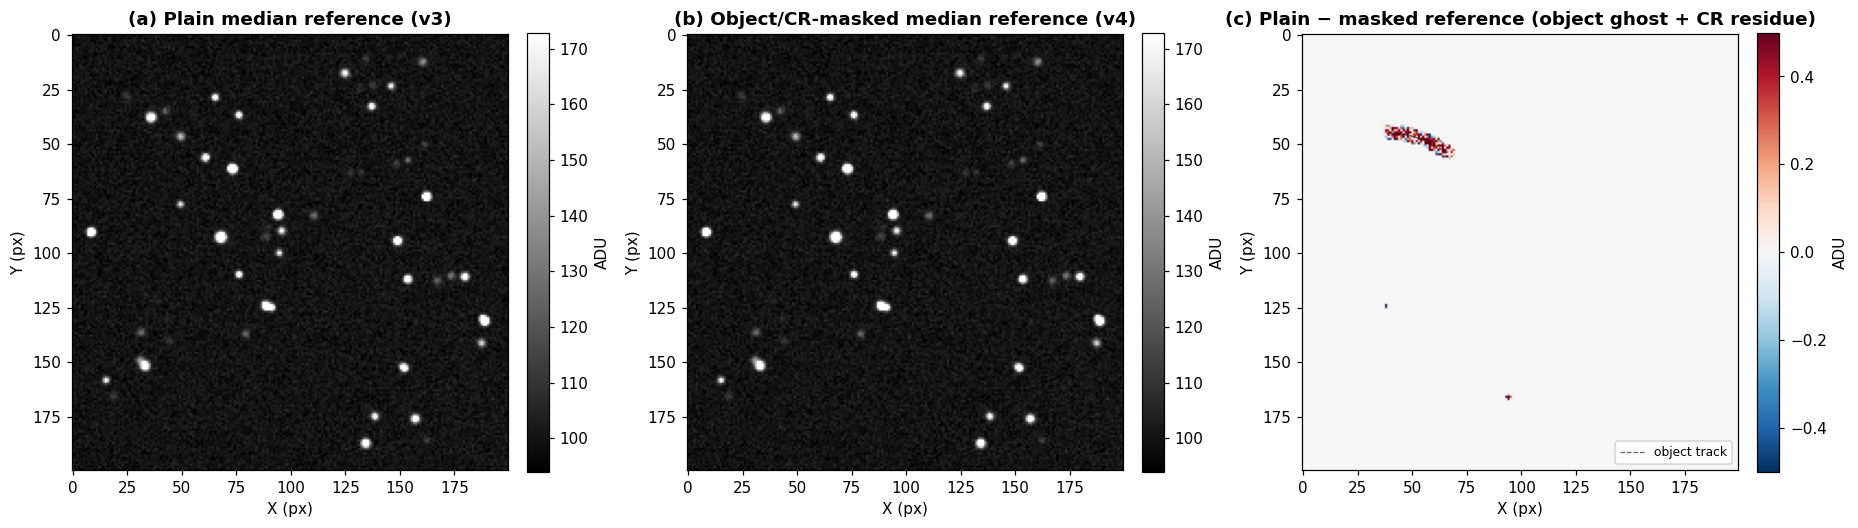

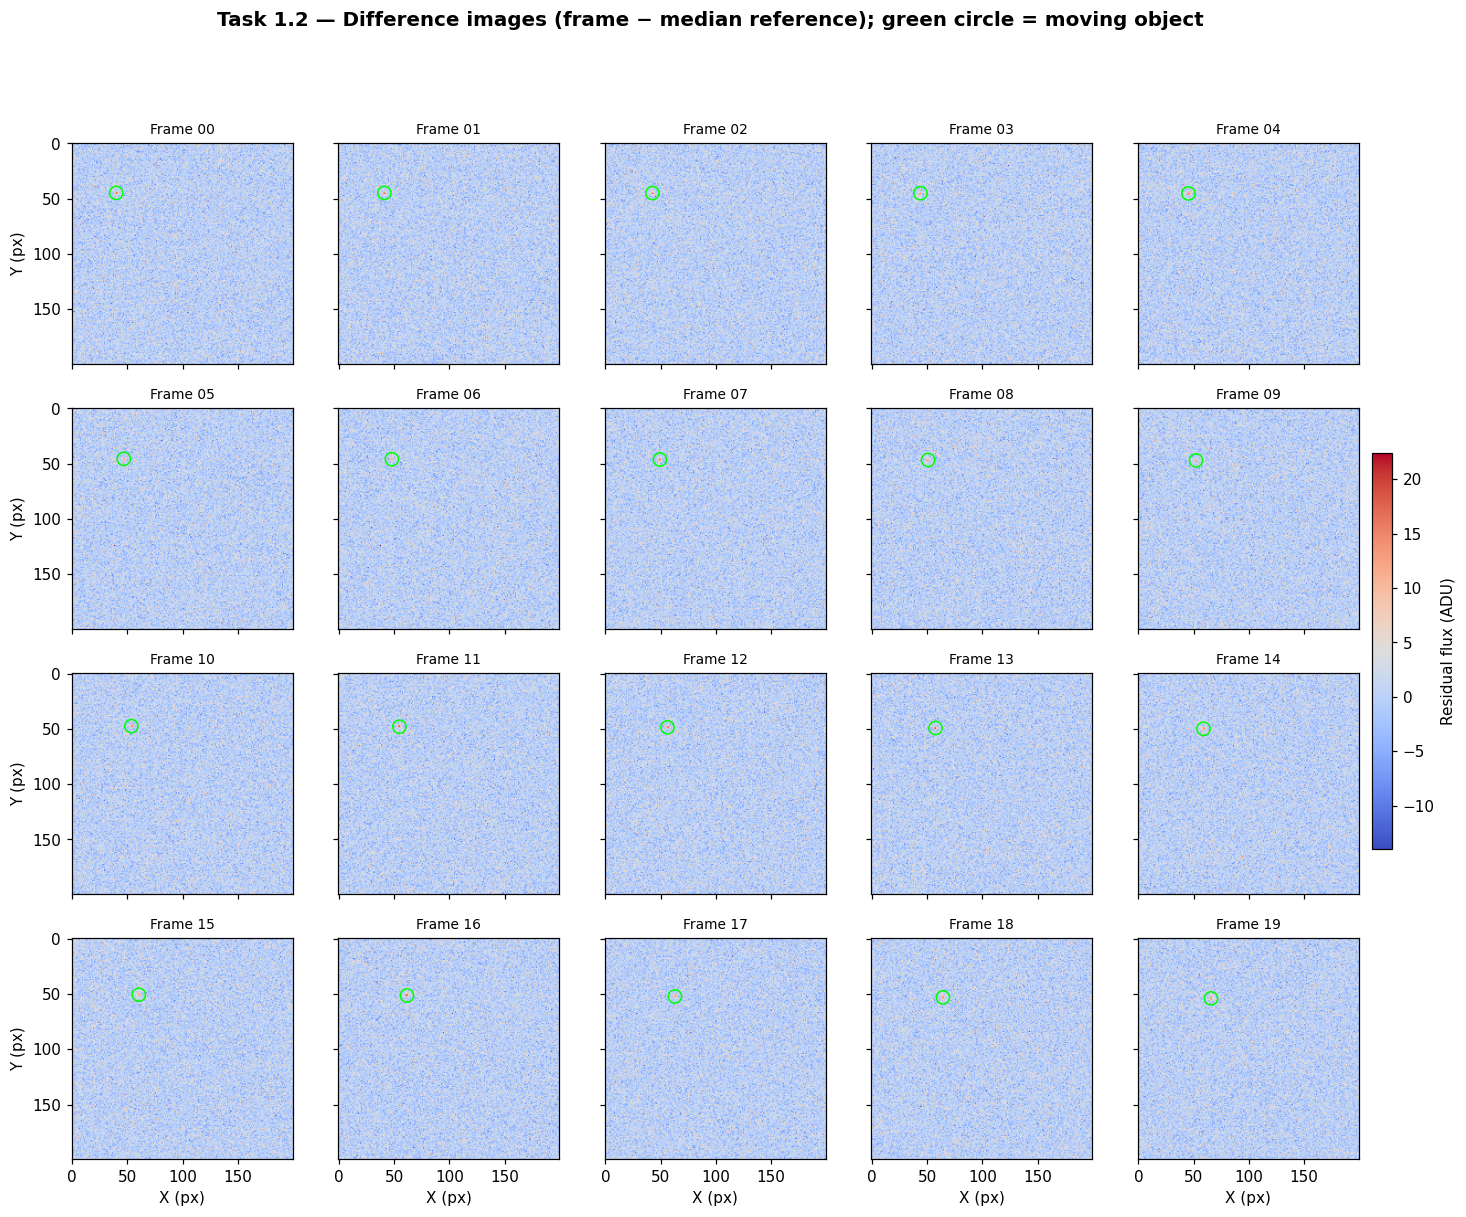

In [6]:
# Step 5 (v4-A): sharpness-based cosmic-ray mask + object-masked median reference + final difference images
excess_plain = np.clip(median_reference - global_bg, 0, None)

def find_cosmic_rays(img, nsig=5.0, sharp=0.30):

    med, sig = sigma_clipped_stats(img)
    z = (img - med) / np.sqrt(sig**2 + 0.5 * excess_plain)
    p = np.pad(z, 1, mode='edge')
    neigh = (p[:-2, 1:-1] + p[2:, 1:-1] + p[1:-1, :-2] + p[1:-1, 2:]) / 4.0
    return (z > nsig) & (z >= maximum_filter(z, size=3)) & (neigh < sharp * z)

cr_masks = np.array([find_cosmic_rays(diff_stack[k]) for k in range(N_frames)])
cr_list = [(k, int(x), int(y), float(diff_stack[k][y, x])) for k in range(N_frames) for y, x in zip(*np.nonzero(cr_masks[k]))]
cr_on_track = sum(np.hypot(x - v3_px(k), y - v3_py(k)) < 2.5 for k, x, y, _ in cr_list)
print(f"v4 cosmic-ray classifier: {len(cr_list)} CR pixels in {N_frames} frames ({cr_on_track} on the object track).")
display(pd.DataFrame(cr_list, columns=['frame', 'x', 'y', 'residual_ADU']))

TRACK_MASK_R = 3.5
yy_full, xx_full = np.mgrid[0:H, 0:W]
track_masks = np.array([(xx_full - v3_px(k))**2 + (yy_full - v3_py(k))**2 < TRACK_MASK_R**2 for k in range(N_frames)])
bad_for_ref = track_masks | np.array([binary_dilation(m, iterations=1) for m in cr_masks])
masked_stack = np.where(bad_for_ref, np.nan, normalized_stack)
median_reference_v4 = np.nanmedian(masked_stack, axis=0)
median_reference_v4 = np.where(np.isfinite(median_reference_v4), median_reference_v4, median_reference)
diff_v4 = normalized_stack - median_reference_v4
sky_sigmas = np.array([sigma_clipped_stats(diff_v4[k])[1] for k in range(N_frames)])


fig, ax = plt.subplots(figsize=(7, 6))
vmin, vmax = np.percentile(median_reference_v4, [1.0, 99.5])
im = ax.imshow(median_reference_v4, cmap='gray', vmin=vmin, vmax=vmax, origin='upper')
ax.set_title("Median Reference Image (object- & cosmic-ray-masked)")
ax.set_xlabel("X Position (pixels)"); ax.set_ylabel("Y Position (pixels)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("Median Flux (ADU)")
fig.savefig(MEDIAN_REF_PATH, bbox_inches='tight'); plt.close(fig)

for idx in range(N_frames):
    s = sky_sigmas[idx]
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    im = ax.imshow(diff_v4[idx], cmap='coolwarm', vmin=-5 * s, vmax=8 * s, origin='upper')
    ax.set_title(f"Difference Image   Frame {idx:02d} (σ = {s:.2f} ADU)")
    ax.set_xlabel("X Position (pixels)"); ax.set_ylabel("Y Position (pixels)")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("Residual Flux (ADU)")
    fig.savefig(os.path.join(DIFF_IMAGES_DIR, f"diff_frame_{idx:02d}.png"), bbox_inches='tight'); plt.close(fig)
print(f"Saved {MEDIAN_REF_PATH} and {N_frames} difference images to {DIFF_IMAGES_DIR}/")


fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, img, ttl in [(axes[0], median_reference, "(a) Plain median reference (v3)"),
                     (axes[1], median_reference_v4, "(b) Object/CR-masked median reference (v4)")]:
    im = ax.imshow(img, cmap='gray', vmin=vmin, vmax=vmax, origin='upper'); ax.set_title(ttl, fontweight='bold')
    ax.set_xlabel("X (px)"); ax.set_ylabel("Y (px)"); fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="ADU")
dref = median_reference - median_reference_v4
lim = max(3 * np.std(dref), 0.5)
im = axes[2].imshow(dref, cmap='RdBu_r', vmin=-lim, vmax=lim, origin='upper')
axes[2].plot(v3_px(np.linspace(0, N_frames - 1, 100)), v3_py(np.linspace(0, N_frames - 1, 100)), 'k--', lw=0.8, alpha=0.6, label='object track')
axes[2].set_title("(c) Plain − masked reference (object ghost + CR residue)", fontweight='bold')
axes[2].set_xlabel("X (px)"); axes[2].set_ylabel("Y (px)"); axes[2].legend(loc='lower right', fontsize=8)
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04, label="ADU")
fig.tight_layout(); fig.savefig(os.path.join(DIAG_DIR, "reference_comparison.png"), bbox_inches='tight'); plt.show()

s_med = float(np.median(sky_sigmas))
montage(diff_v4, "Task 1.2   Difference images (frame − median reference); green circle = moving object",
        "Residual flux (ADU)", cmap='coolwarm', vmin=-5 * s_med, vmax=8 * s_med,
        marks=[(v3_px(k), v3_py(k)) for k in range(N_frames)], path=os.path.join(DIAG_DIR, "difference_montage.png"))

In [8]:
# Step 7 (v4-C/D): joint forward-model fit
def pig(xx, yy, x0, y0, s):

    k = 1.0 / (np.sqrt(2.0) * s)
    return 0.25 * (erf((xx + 0.5 - x0) * k) - erf((xx - 0.5 - x0) * k)) * (erf((yy + 0.5 - y0) * k) - erf((yy - 0.5 - y0) * k))

T_REF = (N_frames - 1) / 2.0
def track_xy(p6, t):
    x0, vx, ax_, y0, vy, ay = p6
    tau = np.asarray(t, float) - T_REF
    return x0 + vx * tau + 0.5 * ax_ * tau**2, y0 + vy * tau + 0.5 * ay * tau**2

STAMP_R = 5
stamps = []
for k in range(N_frames):
    ix, iy = int(round(v3_px(k))), int(round(v3_py(k)))
    sl = (slice(max(0, iy - STAMP_R), min(H, iy + STAMP_R + 1)), slice(max(0, ix - STAMP_R), min(W, ix + STAMP_R + 1)))
    yy, xx = np.mgrid[sl[0], sl[1]]
    stamps.append(dict(k=k, xx=xx, yy=yy, d=diff_v4[k][sl], n=noise_maps[k][sl], good=~cr_masks[k][sl]))

def joint_resid(theta, full=False):
    s, fl, off = theta[6], theta[7:7 + N_frames], theta[7 + N_frames:]
    xc, yc = track_xy(theta[:6], t_arr)
    r = [((st['d'] - off[st['k']] - fl[st['k']] * pig(st['xx'], st['yy'], xc[st['k']], yc[st['k']], s)) / st['n_eff'])
         for st in stamps]
    return r if full else np.concatenate([ri[st['good']] for ri, st in zip(r, stamps)])

c2x, c1x, c0x = v3_px.coeffs; c2y, c1y, c0y = v3_py.coeffs
p6_0 = [v3_px(T_REF), 2 * c2x * T_REF + c1x, 2 * c2x, v3_py(T_REF), 2 * c2y * T_REF + c1y, 2 * c2y]
flux0 = []
for st in stamps:
    P = pig(st['xx'], st['yy'], v3_px(st['k']), v3_py(st['k']), 1.12)
    flux0.append(max(np.sum(st['d'] * P) / np.sum(P * P), 5.0))
theta0 = np.r_[p6_0, 1.12, flux0, np.zeros(N_frames)]
lb = np.r_[[-np.inf] * 6, 0.5, np.zeros(N_frames), -10 * np.ones(N_frames)]
ub = np.r_[[np.inf] * 6, 3.0, np.full(N_frames, np.inf), 10 * np.ones(N_frames)]


for st in stamps:
    st['good'] = np.ones_like(st['d'], dtype=bool); st['n_eff'] = st['n'].copy()
for _pass in range(3):
    jres = least_squares(joint_resid, theta0, bounds=(lb, ub), x_scale='jac', max_nfev=5000)
    theta0 = jres.x
    xc, yc = track_xy(theta0[:6], t_arr)
    for st in stamps:
        mdl = theta0[7 + st['k']] * pig(st['xx'], st['yy'], xc[st['k']], yc[st['k']], theta0[6])
        st['n_eff'] = np.sqrt(st['n']**2 + b_noise * np.clip(mdl, 0, None))
    for st, ri in zip(stamps, joint_resid(theta0, full=True)):
        st['good'] = np.abs(ri) < 5.0
jres = least_squares(joint_resid, theta0, bounds=(lb, ub), x_scale='jac', max_nfev=5000)
theta_joint = jres.x
print(f"Joint fit rejected {sum((~st['good']).sum() for st in stamps)} outlier pixels.")
n_res, n_par = jres.fun.size, theta_joint.size
chi2r_joint = float(np.sum(jres.fun**2) / (n_res - n_par))
cov_joint = np.linalg.pinv(jres.jac.T @ jres.jac) * max(1.0, chi2r_joint)
err_joint = np.sqrt(np.diag(cov_joint))
sigma_psf_global = float(theta_joint[6])

names = ['x_mid', 'v_x', 'a_x', 'y_mid', 'v_y', 'a_y', 'sigma_psf']
units = ['px', 'px/frame', 'px/frame²', 'px', 'px/frame', 'px/frame²', 'px']
df_joint = pd.DataFrame({'parameter': names, 'value': theta_joint[:7], 'error_1sigma': err_joint[:7], 'unit': units})
df_joint['significance_sigma'] = np.abs(df_joint.value / df_joint.error_1sigma)
print(f"Joint fit: {n_res} pixels, {n_par} parameters, reduced χ² = {chi2r_joint:.3f}; "
      f"σ_PSF = {sigma_psf_global:.3f} px (FWHM {2.3548 * sigma_psf_global:.2f} px); t_mid = frame {T_REF}")
display(df_joint.round(5))

Joint fit rejected 0 outlier pixels.
Joint fit: 2420 pixels, 47 parameters, reduced χ² = 1.141; σ_PSF = 1.074 px (FWHM 2.53 px); t_mid = frame 9.5


,parameter,value,error_1sigma,unit,significance_sigma
0,x_mid,52.82339,0.05053,px,1045.28738
1,v_x,1.35708,0.00570,px/frame,238.15951
2,a_x,-0.00130,0.00219,px/frame²,0.59259
3,y_mid,47.25915,0.05052,px,935.53079
4,v_y,0.47749,0.00570,px/frame,83.79026
5,a_y,0.04705,0.00219,px/frame²,21.50754
6,sigma_psf,1.07384,0.02656,px,40.42859


In [9]:
# Step 8 (v4-E/F): per-frame astrometry with σ_PSF fixed, then kinematic model selection
def fit_frame_psf(img, noise_img, bad, cx, cy, s_psf, radius=4, max_shift=2.0, b_src=None):
    b_src = b_noise if b_src is None else b_src
    ix, iy = int(round(cx)), int(round(cy))
    sl = (slice(max(0, iy - radius), min(H, iy + radius + 1)), slice(max(0, ix - radius), min(W, ix + radius + 1)))
    yy, xx = np.mgrid[sl[0], sl[1]]
    d, n = img[sl], noise_img[sl]
    good = np.ones_like(d, dtype=bool)
    P0 = pig(xx, yy, cx, cy, s_psf)
    f0 = max(np.sum(d * P0) / np.sum(P0 * P0), 1.0)
    n_eff = n.copy()
    full = lambda p: (d - p[3] - p[0] * pig(xx, yy, p[1], p[2], s_psf)) / n_eff
    p = [f0, cx, cy, 0.0]



    for _pass in range(3):
        r = least_squares(lambda q: full(q)[good], p, x_scale=[max(f0, 10) * 0.1, 0.1, 0.1, 0.5],
                          bounds=([0.0, cx - max_shift, cy - max_shift, -10.0], [np.inf, cx + max_shift, cy + max_shift, 10.0]))
        p = r.x
        n_eff = np.sqrt(n**2 + b_src * np.clip(p[0] * pig(xx, yy, p[1], p[2], s_psf), 0, None))
        good = np.abs(full(p)) < 5.0
    r = least_squares(lambda q: full(q)[good], p, x_scale=[max(f0, 10) * 0.1, 0.1, 0.1, 0.5],
                      bounds=([0.0, cx - max_shift, cy - max_shift, -10.0], [np.inf, cx + max_shift, cy + max_shift, 10.0]))
    p = r.x
    good_fit = good
    cov = np.linalg.pinv(r.jac.T @ r.jac)
    e = np.sqrt(np.diag(cov))
    return dict(flux=r.x[0], x=r.x[1], y=r.x[2], offset=r.x[3], e_flux=e[0], ex=e[1], ey=e[2],
                chi2r=float(np.sum(r.fun**2) / max(good_fit.sum() - 4, 1)), n_rej=int((~good_fit).sum()), model_stamp=(sl, r.x))

rows = []
for k in range(N_frames):
    f = fit_frame_psf(diff_v4[k], noise_maps[k], cr_masks[k], df_v3.x[k], df_v3.y[k], sigma_psf_global)
    ix, iy = int(round(f['x'])), int(round(f['y']))
    pk = float(np.max(diff_v4[k][max(0, iy - 1):iy + 2, max(0, ix - 1):ix + 2]))
    ap = float(np.sum(diff_v4[k][max(0, iy - 1):iy + 2, max(0, ix - 1):ix + 2]))
    rows.append({'frame': k, 'x': f['x'], 'y': f['y'], 'x_err': f['ex'], 'y_err': f['ey'],
                 'pos_err_px': float(np.hypot(f['ex'], f['ey'])), 'flux_ADU': f['flux'], 'flux_err_ADU': f['e_flux'],
                 'psf_snr': f['flux'] / f['e_flux'], 'peak_snr': pk / sky_sigmas[k], 'ap_snr': ap / (3 * sky_sigmas[k]),
                 'bg_sigma': sky_sigmas[k], 'fit_chi2r': f['chi2r']})
df_v4 = pd.DataFrame(rows)
x_arr, y_arr, ex_arr, ey_arr = df_v4.x.values, df_v4.y.values, df_v4.x_err.values, df_v4.y_err.values

def kinematic_model_selection(t, x, y, ex, ey, degs=(1, 2, 3)):
    out, n = [], 2 * len(t)
    for deg in degs:
        cx_ = np.polyfit(t, x, deg, w=1 / ex); cy_ = np.polyfit(t, y, deg, w=1 / ey)
        rx, ry = x - np.polyval(cx_, t), y - np.polyval(cy_, t)
        chi2 = float(np.sum((rx / ex)**2 + (ry / ey)**2)); k = 2 * (deg + 1)
        loo = []
        for i in range(len(t)):
            m = np.arange(len(t)) != i
            px_ = np.polyfit(t[m], x[m], deg, w=1 / ex[m]); py_ = np.polyfit(t[m], y[m], deg, w=1 / ey[m])
            loo.append(np.hypot(x[i] - np.polyval(px_, t[i]), y[i] - np.polyval(py_, t[i])))
        out.append({'model': {1: 'linear', 2: 'quadratic', 3: 'cubic'}[deg], 'n_params': k, 'chi2': chi2, 'dof': n - k,
                    'chi2_per_dof': chi2 / (n - k), 'BIC': chi2 + k * np.log(n), 'AIC': chi2 + 2 * k,
                    'RMS_2D_px': float(np.sqrt(np.mean(rx**2 + ry**2))), 'LOO_CV_RMS_px': float(np.sqrt(np.mean(np.square(loo)))),
                    'R2_x': 1 - np.sum(rx**2) / np.sum((x - x.mean())**2), 'R2_y': 1 - np.sum(ry**2) / np.sum((y - y.mean())**2)})
    df = pd.DataFrame(out)
    for a, b in [(0, 1), (1, 2)]:
        F = ((df.chi2[a] - df.chi2[b]) / (df.n_params[b] - df.n_params[a])) / (df.chi2[b] / df.dof[b])
        df.loc[b, 'F_test_p_vs_simpler'] = stats.f.sf(F, df.n_params[b] - df.n_params[a], df.dof[b])
    return df

sel_v4 = kinematic_model_selection(t_arr, x_arr, y_arr, ex_arr, ey_arr)
e3 = df_v3.pos_err_px.values / np.sqrt(2)
sel_v3 = kinematic_model_selection(t_arr, df_v3.x.values, df_v3.y.values, e3, e3)
print("Kinematic model selection   v4 measurements (lowest BIC wins):")
display(sel_v4.round(5))
best_model = sel_v4.loc[sel_v4.BIC.idxmin(), 'model']
print(f"Preferred model by BIC: {best_model}")


tau = t_arr - T_REF
qx = np.polyfit(tau, x_arr, 2, w=1 / ex_arr); qy = np.polyfit(tau, y_arr, 2, w=1 / ey_arr)
p2x = lambda t: np.polyval(qx, np.asarray(t) - T_REF); p2y = lambda t: np.polyval(qy, np.asarray(t) - T_REF)
lx = np.polyfit(t_arr, x_arr, 1, w=1 / ex_arr); ly = np.polyfit(t_arr, y_arr, 1, w=1 / ey_arr)
t_fine = np.linspace(0, N_frames - 1, 300)
boot, band_x, band_y = [], [], []
for _ in range(2000):
    i = rng.integers(0, N_frames, N_frames)
    if len(np.unique(i)) < 4:
        continue
    bx = np.polyfit(tau[i], x_arr[i], 2, w=1 / ex_arr[i]); by = np.polyfit(tau[i], y_arr[i], 2, w=1 / ey_arr[i])
    boot.append([bx[1], by[1], 2 * bx[0], 2 * by[0]])
    band_x.append(np.polyval(bx, t_fine - T_REF)); band_y.append(np.polyval(by, t_fine - T_REF))
boot = np.array(boot)
bx_lo, bx_hi = np.percentile(band_x, [16, 84], axis=0); by_lo, by_hi = np.percentile(band_y, [16, 84], axis=0)
kin = pd.DataFrame({'quantity': ['v_x (t_mid)', 'v_y (t_mid)', 'a_x', 'a_y'], 'unit': ['px/fr', 'px/fr', 'px/fr²', 'px/fr²'],
                    'weighted_fit': [qx[1], qy[1], 2 * qx[0], 2 * qy[0]],
                    'bootstrap_median': np.median(boot, 0), 'bootstrap_1sigma': np.std(boot, 0),
                    'joint_fit': theta_joint[[1, 4, 2, 5]], 'joint_fit_1sigma': err_joint[[1, 4, 2, 5]]})


kin['adopted_1sigma'] = np.maximum(kin.joint_fit_1sigma, kin.bootstrap_1sigma)
kin['significance_sigma'] = np.abs(kin.joint_fit / kin.adopted_1sigma)
display(kin.round(5))

res_x, res_y = x_arr - p2x(t_arr), y_arr - p2y(t_arr)
df_v4['quad_pred_x'], df_v4['quad_pred_y'] = p2x(t_arr), p2y(t_arr)
df_v4['residual_px'] = np.hypot(res_x, res_y)
df_v4['status'] = 'Direct PSF Detection'
m4 = v3_style_metrics(t_arr, x_arr, y_arr, 1 / np.hypot(ex_arr, ey_arr))

Kinematic model selection   v4 measurements (lowest BIC wins):


,model,n_params,chi2,dof,chi2_per_dof,BIC,AIC,RMS_2D_px,LOO_CV_RMS_px,R2_x,R2_y,F_test_p_vs_simpler
0,linear,4,582.81108,36,16.18920,597.56660,590.81108,0.73602,0.84604,0.99968,0.93563,NaN
1,quadratic,6,43.84815,34,1.28965,65.98142,55.84815,0.21314,0.25318,0.99969,0.99676,0.00000
2,cubic,8,39.78202,32,1.24319,69.29305,55.78202,0.20452,0.26523,0.99973,0.99686,0.21075


Preferred model by BIC: quadratic


,quantity,unit,weighted_fit,bootstrap_median,bootstrap_1sigma,joint_fit,joint_fit_1sigma,adopted_1sigma,significance_sigma
0,v_x (t_mid),px/fr,1.35852,1.35942,0.00674,1.35708,0.00570,0.00674,201.20269
1,v_y (t_mid),px/fr,0.47737,0.47681,0.00686,0.47749,0.00570,0.00686,69.60942
2,a_x,px/fr²,-0.00141,-0.00159,0.00264,-0.00130,0.00219,0.00264,0.49151
3,a_y,px/fr²,0.04720,0.04729,0.00276,0.04705,0.00219,0.00276,17.01830


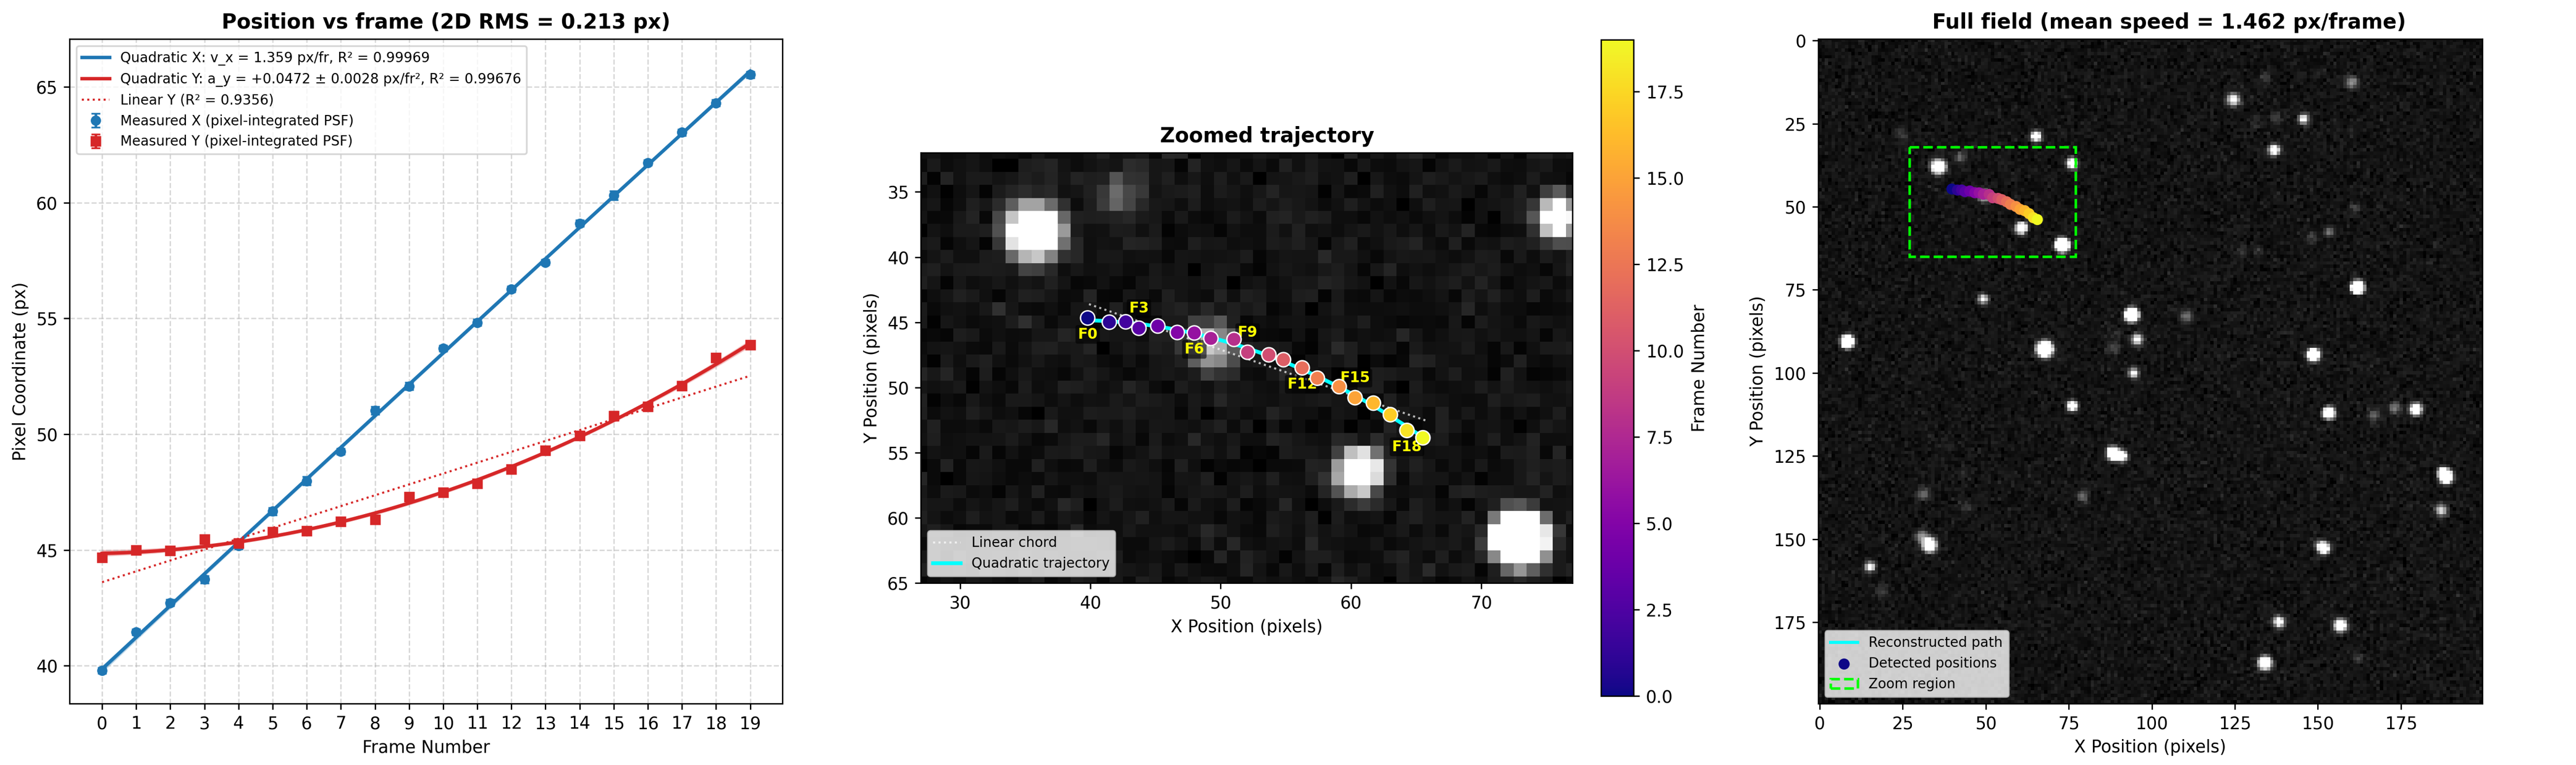

Saved trajectory figure: The gentlemen_trajectory1.png


In [12]:
# Step 11: final trajectory figure (deliverable teamname_trajectory1.png)
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(21, 6.5))

a1.fill_between(t_fine, bx_lo, bx_hi, color='#1f77b4', alpha=0.25)
a1.fill_between(t_fine, by_lo, by_hi, color='#d62728', alpha=0.25)
a1.errorbar(t_arr, x_arr, yerr=ex_arr, fmt='o', color='#1f77b4', ms=5, capsize=2.5, label='Measured X (pixel-integrated PSF)')
a1.errorbar(t_arr, y_arr, yerr=ey_arr, fmt='s', color='#d62728', ms=5, capsize=2.5, label='Measured Y (pixel-integrated PSF)')
a1.plot(t_fine, p2x(t_fine), '-', color='#1f77b4', lw=2, label=f"Quadratic X: v_x = {qx[1]:.3f} px/fr, R² = {m4['R2x']:.5f}")
a1.plot(t_fine, p2y(t_fine), '-', color='#d62728', lw=2,
        label=f"Quadratic Y: a_y = {2 * qy[0]:+.4f} ± {kin.adopted_1sigma[3]:.4f} px/fr², R² = {m4['R2y']:.5f}")
a1.plot(t_fine, np.polyval(ly, t_fine), ':', color='#d62728', lw=1.2, label=f"Linear Y (R² = {m4['R2y_lin']:.4f})")
a1.set_title(f"Position vs frame (2D RMS = {m4['rms_quad']:.3f} px)", fontweight='bold')
a1.set_xlabel("Frame Number"); a1.set_ylabel("Pixel Coordinate (px)"); a1.set_xticks(t_arr); a1.grid(alpha=0.5, ls='--'); a1.legend(fontsize=8, loc='upper left')

pad = 12
zx0, zx1 = max(0, int(x_arr.min()) - pad), min(W, int(x_arr.max()) + pad)
zy0, zy1 = max(0, int(y_arr.min()) - pad), min(H, int(y_arr.max()) + pad)

vmin, vmax = np.percentile(median_reference_v4, [1.0, 99.5])
a2.imshow(median_reference_v4, cmap='gray', vmin=vmin, vmax=vmax, origin='upper')
a2.plot(np.polyval(lx, t_fine), np.polyval(ly, t_fine), ':', color='white', lw=1.2, alpha=0.7, label='Linear chord')
a2.plot(p2x(t_fine), p2y(t_fine), '-', color='cyan', lw=2.2, label='Quadratic trajectory')
sc = a2.scatter(x_arr, y_arr, c=t_arr, cmap='plasma', s=70, edgecolors='white', lw=0.8, zorder=6)
for i in range(0, N_frames, 3):
    a2.annotate(f"F{i}", (x_arr[i], y_arr[i]), textcoords='offset points', xytext=(0, 9 if i % 2 else -12), ha='center',
                color='yellow', fontsize=8.5, weight='bold', bbox=dict(boxstyle='round,pad=0.15', fc='black', alpha=0.6, ec='none'))
a2.set_xlim(zx0, zx1); a2.set_ylim(zy1, zy0)
a2.set_title("Zoomed trajectory", fontweight='bold'); a2.set_xlabel("X Position (pixels)"); a2.set_ylabel("Y Position (pixels)")
fig.colorbar(sc, ax=a2, fraction=0.046, pad=0.04).set_label("Frame Number"); a2.legend(fontsize=8, loc='lower left')

a3.imshow(median_reference_v4, cmap='gray', vmin=vmin, vmax=vmax, origin='upper')
a3.plot(p2x(t_fine), p2y(t_fine), '-', color='cyan', lw=1.8, label='Reconstructed path')
a3.scatter(x_arr, y_arr, c=t_arr, cmap='plasma', s=30, zorder=5, label='Detected positions')
a3.add_patch(Rectangle((zx0, zy0), zx1 - zx0, zy1 - zy0, lw=1.5, ec='lime', fc='none', ls='--', label='Zoom region'))
speed = np.hypot(np.gradient(p2x(t_arr)), np.gradient(p2y(t_arr)))
a3.set_title(f"Full field (mean speed = {speed.mean():.3f} px/frame)", fontweight='bold')
a3.set_xlabel("X Position (pixels)"); a3.set_ylabel("Y Position (pixels)"); a3.legend(fontsize=8, loc='lower left')

fig.tight_layout(); fig.savefig(TRAJECTORY_PATH, bbox_inches='tight'); plt.show()
print(f"Saved trajectory figure: {TRAJECTORY_PATH}")